# Lesson 15. The color from the other side

[Course plan](../../README.md)

A gray ball stays gray as the camera travels around it. Yet a small patch on a glazed cup can look redder in one photograph than in the next. The same stationary part of a scene can have different observed colors. We start with a splat whose red channel alone can vary.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo
lang = "en"

## A frame where only the color changes

The camera always aims at the center of one round splat with equal scale along all three axes. The distance stays fixed as well. On the left the splat has a fixed RGB. On the right a direction-dependent value is added to the same RGB. Opacity at the center is one, so this pixel shows the splat color itself. Near the edges the white background mixes in.

With all three directional coefficients at zero, the right frame matches the left at every azimuth. One nonzero coefficient reveals which side of the sphere gains red. Elevating the camera introduces a vertical component.

In [2]:
display(demo.experiment(15, "en"))

A second splat on the rim of the cup could slide in front of this patch as the camera moved. That would be the effect from the previous lesson. Here we can take it out of the experiment. There is one splat, and its opacity and the background stay fixed. The camera orbits at a fixed distance and keeps looking at its center. The middle pixel follows the same point all the way around. Any change in red there comes from the new color rule.

A horizontal orbit makes a good first check. With elevation set to zero the viewing ray stays in the $xz$ plane. The vertical coefficient can be one, or minus one, and the two frames still look exactly the same. The multiplication below will show where it disappears. A camera above or below that plane gives the coefficient a chance to show up.

## A direction of length one

In a numerical example the camera center is $K=(-3,0,0)$ and the splat center is $P=(0,0,4)$. The arrow **from camera to splat** is $P-K=(3,0,4)$. Its length by Pythagoras is $r=\sqrt{3^2+0^2+4^2}=\sqrt{25}=5$. Dividing each component by five gives $d=(0.6,0,0.8)$. Its length is now one because $0.6^2+0.8^2=1$. Direction has no units, and distance alone no longer changes the color. A camera another five units back along the same line yields the same normalized arrow.

The tips of all such unit arrows lie on a sphere. A camera exactly at the splat center would yield a zero arrow and no direction. The renderer already skips that center in its depth test. Positive $y$ points down in the initial camera's world. Color coefficients refer to world axes, so turning the camera body in place does not by itself change the color of a point.

In [3]:
direction = np.array([3., 0., 4.])
print(direction / np.linalg.norm(direction))
print(np.round(sr.sh_basis(direction), 6))
np.testing.assert_allclose(sr.sh_basis(direction), sr.sh_basis(2*direction))

[0.6 0.  0.8]
[ 0.282095 -0.        0.390882 -0.293162]


## Four maps on the same sphere

A **spherical harmonic** here is a fixed rule that returns a number for a direction. The collection of these rules forms a basis. The first map has one value everywhere on the sphere. Three more maps change sign smoothly between opposite sides. A **function** determines the pattern on each map. A **coefficient** says how much of that pattern belongs to one splat's color.

The renderer of Kerbl et al. uses the first four real functions in this order:

$$
(Y_0,Y_y,Y_z,Y_x)=(C_0,-C_1d_y,+C_1d_z,-C_1d_x).
$$

Here $C_0=1/\sqrt{4\pi}\approx0.282095$ and $C_1=\sqrt{3/(4\pi)}\approx0.488603$. The number $\pi\approx3.14159$ relates a circle's radius and circumference. These constants give each function the same total squared value across the sphere. For a unit sphere the area is $4\pi$. The constant map gives $4\pi C_0^2=1$. For the $x$ map, the average of $x^2$ over the sphere is $1/3$: the axes are equivalent and $x^2+y^2+z^2=1$. Thus $4\pi C_1^2/3=1$. In the image the normalization constant and the learned coefficient always act together.

At $(0.6,0,0.8)$ the four map values are $(0.282095,0,0.390882,-0.293162)$. A negative basis value is useful. It subtracts a contribution from the channel before we turn that channel into a display intensity.

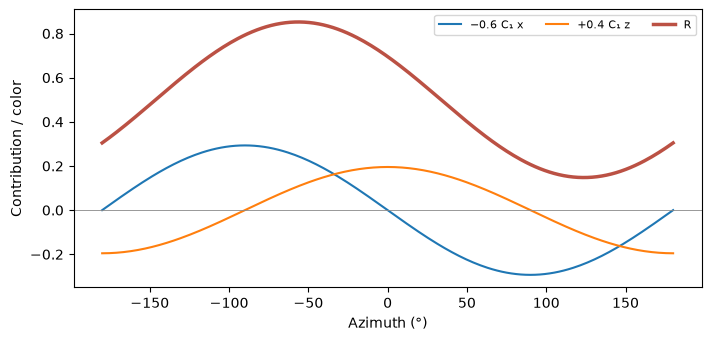

In [4]:
fig = demo.harmonic_curve("en")
display(fig)
plt.close(fig)

## From the maps to the red channel

The example uses four coefficients for red, $a=(0,0,0.4,0.6)$. In the original GS encoding a constant offset of $0.5$ gives gray when all coefficients are zero. We multiply each basis value by its coefficient and add:

$$
\begin{aligned}
R &= 0.5+a_0Y_0+a_yY_y+a_zY_z+a_xY_x \\
  &= 0.5+0+0+0.4\cdot0.390882+0.6\cdot(-0.293162)\\
  &\approx 0.5+0.156353-0.175897=0.480456.
\end{aligned}
$$

Green and blue have zero coefficients and the resulting triple is $(0.480456,0.5,0.5)$. For a constant red of $0.8$, we solve $0.8=0.5+a_0 C_0$. Subtracting $0.5$ and dividing $0.3$ by $0.282095$ gives $a_0\approx1.0635$. A coefficient can exceed one. For display we clip each final channel to $[0,1]$. At this stage the original CUDA SH calculation clips only negative values. The location of that clamp matters when training with very bright colors.

In [5]:
coeff = np.array([[0,0,0], [0,0,0], [.4,0,0], [.6,0,0]])
for d in ([.6,0,.8], [-.6,0,-.8]):
    print(d, np.round(sr.sh_color(d, coeff), 6))
constant = [[(.8-.5)/sr.C0, 0, 0]]
np.testing.assert_allclose(sr.sh_color([0,0,1], constant), [.8,.5,.5])

[0.6, 0, 0.8] [0.480456 0.5      0.5     ]
[-0.6, 0, -0.8] [0.519544 0.5      0.5     ]


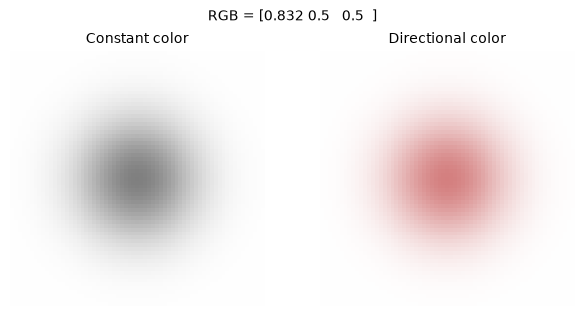

In [6]:
fig = demo.harmonic_figure("en")
display(fig)
plt.close(fig)

The caption and the hand calculation give different reds. The hand calculation used $(+0.6,0,+0.8)$. The frame has azimuth $-36.87^\circ$, so $x$ has changed sign while $z$ has stayed the same. The $x$ map now **adds** $0.175897$. The pixel comes out to $0.5+0.156353+0.175897\approx0.83225$. These are two front views from different sides. Going all the way to the opposite side would reverse $z$ as well, as in the printed calculation above the frame.

## Working backward from six photographs

So far we had numbers for the splat and used them to make an image. With the glazed cup it is the other way around. We can measure a color in each photograph, we know the camera, and somehow we have to put coefficients in the scene file. An isolated opaque splat gives us a case where we can trace each number back to the observation that determined it. The cameras aim at its center. For now we only measure red.

Suppose there is one camera on each side of each coordinate axis. The table records the ray **from camera to splat**. A positive $x$ ray means the camera is on the negative $x$ side. Only one direction component is nonzero in each row, so the contribution from an axis can be seen in isolation.

| Ray direction | Red at the center |
|---|---:|
| $(+1,0,0)$ | 0.75 |
| $(-1,0,0)$ | 0.35 |
| $(0,+1,0)$ | 0.45 |
| $(0,-1,0)$ | 0.65 |
| $(0,0,+1)$ | 0.70 |
| $(0,0,-1)$ | 0.40 |

For the moment we can absorb the constants $C_0,C_1$ into four easier numbers. Let $b$ be the constant part of the color, including the $0.5$ offset. Three more numbers, $g_x,g_y,g_z$, tell us how much each unit component of the direction contributes. Before clipping, red is

$$
R(d)=b+g_x d_x+g_y d_y+g_z d_z.
$$

On the left and right rays everything except the $x$ term drops out. The two equations are $0.75=b+g_x$ and $0.35=b-g_x$. Adding them gives $1.10$ on the left and $2b$ on the right. Half the sum gives $b=0.55$. Subtracting them instead eliminates $b$. Half the difference gives $g_x=(0.75-0.35)/2=0.20$. The table now has a simple reading. One side gains $0.20$ red above the baseline and the other loses the same amount. This average works for a pair of **opposite** directions. The terms would generally fail to cancel for two arbitrary cameras.

The two vertical readings have the same mean $0.55$, but their difference has the opposite sign. We get $g_y=(0.45-0.65)/2=-0.10$. The remaining pair gives $g_z=(0.70-0.40)/2=0.15$. That is enough to predict a view missing from the table. At $d=(0,0.6,0.8)$ the direction already has length one. Red is $0.55+0-0.10\cdot0.6+0.15\cdot0.8=0.61$. Green and blue could have quite different coefficients. All three channels use the same ray.

To get back to the maps, we can match terms in the two formulas. The factor in front of $d_x$ used to be $-C_1a_x$, so $a_x=-g_x/C_1$. The $y$ map has the same minus sign, while the $z$ map has a plus. The constant coefficient is $a_0=(b-0.5)/C_0$. After division, the red coefficients in file order $(a_0,a_y,a_z,a_x)$ are approximately $(0.1772,0.2047,0.3070,-0.4093)$. The last one is negative even though red *increased* on the positive $x$ ray. Its sign compensates for the minus in the definition of the map.

In [7]:
rays = np.array([[1, 0, 0], [-1, 0, 0], [0, 1, 0],
                 [0, -1, 0], [0, 0, 1], [0, 0, -1]])
measured = np.array([.75, .35, .45, .65, .70, .40])
basis = np.stack([sr.sh_basis(ray) for ray in rays])
fitted_red, _, rank, _ = np.linalg.lstsq(basis, measured - .5, rcond=None)
held_out = np.array([0., .6, .8])
coeff = np.zeros((4, 3))
coeff[:, 0] = fitted_red
print("a =", np.round(fitted_red, 5))
print("R(0, 0.6, 0.8) =", round(sr.sh_color(held_out, coeff)[0], 5))
assert rank == 4
np.testing.assert_allclose(.5 + basis @ fitted_red, measured)
np.testing.assert_allclose(sr.sh_color(held_out, coeff)[0], .61)

a = [ 0.17725  0.20467  0.307   -0.40933]
R(0, 0.6, 0.8) = 0.61


Each row of `basis` holds four map values for one camera. The $(+1,0,0)$ ray has row $(C_0,0,0,-C_1)$, for example. Multiplying that row by the coefficient column adds up the four contributions to one observation. The renderer supplies the $0.5$ offset independently, so the fit subtracts it from the measurements. `lstsq` chooses coefficients that minimize the sum of squared mismatches across the rows. All six equations happen to agree in this constructed example, and their residual is zero to rounding accuracy. In a photograph even a single noisy reading can spoil the agreement between the three pair averages.

## Four cameras that leave an axis invisible

Now keep only $+x,-x,+z,-z$. Four measurements, four unknowns. That sounds promising until we look at the directions. Every camera stayed in the horizontal plane, so every row has a zero in the $a_y$ column. Another hundred cameras on that orbit would still give a column full of zeros. Two quite different values, say $g_y=-0.10$ and $g_y=+0.20$, explain **all** those photographs equally well. Only three independent combinations of coefficients are constrained. That is what `rank = 3` will tell us in the calculation.

The solver below returns zero for the unconstrained coefficient. This gives the shortest coefficient vector among the solutions that fit. The zero comes from the solver's choice. There is no evidence for it in the measurements. At the new direction $(0,0.6,0.8)$ it predicts $0.55+0+0.12=0.67$, while our observation there was $0.61$. With $g_y=+0.20$ it would predict $0.55+0.12+0.12=0.79$. The three curves pass through the same point at $d_y=0$, then pull apart as the camera leaves that orbit.

One extra measurement along $(0,+1,0)$ resolves the ambiguity. We measured $0.45$ there and already know the baseline is $0.55$. Their difference $0.45-0.55=-0.10$ recovers the missing $g_y$. The camera at $(0,0.6,0.8)$ can still be kept out of the fit. It has supplied no coefficients, so its color tests an actual prediction.

rank = 3
R = [0.67 0.79 0.61]


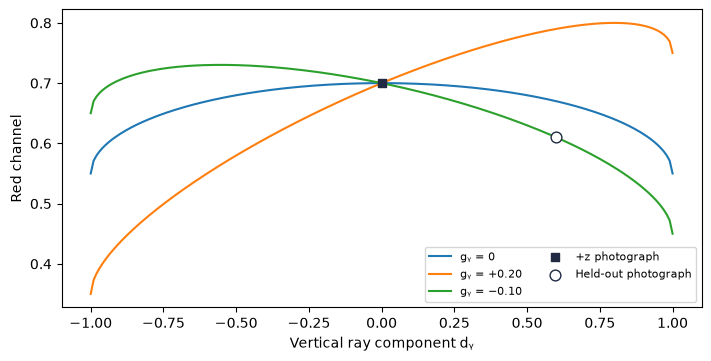

In [8]:
flat = [0, 1, 4, 5]
plane_red, _, plane_rank, _ = np.linalg.lstsq(basis[flat], measured[flat] - .5, rcond=None)
one_more = flat + [2]
recovered = np.linalg.lstsq(basis[one_more], measured[one_more] - .5, rcond=None)[0]
also_fits = plane_red.copy()
also_fits[1] = -.20 / sr.C1
for estimate in (plane_red, also_fits, recovered):
    np.testing.assert_allclose(.5 + basis[flat] @ estimate, measured[flat])
print("rank =", plane_rank)
predictions = [.5 + sr.sh_basis(held_out) @ a for a in (plane_red, also_fits, recovered)]
print("R =", np.round(predictions, 3))
np.testing.assert_allclose(predictions, [.67, .79, .61])
assert plane_rank == 3

vertical = np.linspace(-1., 1., 201)
section = np.array([sr.sh_basis([0, y, np.sqrt(1 - y*y)]) for y in vertical])
ru = lang == "ru"
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
for label, a in [("gᵧ = 0", plane_red), ("gᵧ = +0.20", also_fits), ("gᵧ = −0.10", recovered)]:
    ax.plot(vertical, .5 + section @ a, label=label)
ax.scatter([0], [.70], marker="s", color="#202a42", zorder=4,
           label="Снимок +z" if ru else "+z photograph")
ax.scatter([.6], [.61], marker="o", s=60, facecolors="white", edgecolors="#202a42", zorder=4,
           label="Отложенный снимок" if ru else "Held-out photograph")
ax.set(xlabel="Вертикальная компонента луча dᵧ" if ru else "Vertical ray component dᵧ",
       ylabel="Красный канал" if ru else "Red channel")
ax.legend(fontsize=8, ncol=2)
display(fig)
plt.close(fig)

The splat stays at the same distance from the camera throughout this sweep. The curves have $d_x=0$ and $d_z=\sqrt{1-d_y^2}$, keeping the ray on the front half of the unit sphere. The solid square belongs to the fit. The open circle is the held-out photograph for the four-camera model and stays held out after adding the vertical camera. The different slopes are what let the circle distinguish a good prediction from several good fits to the horizontal views.

## What the photograph actually measured

At an opaque center we could read the color straight from a pixel. Repeating that operation near the edge would assign different coefficients to the very same material. Suppose the cup has red $c=0.70$, the background has $B=1$, and the local opacity is $\alpha=0.5$. The pixel from the previous lesson is $I=\alpha c+(1-\alpha)B=0.5\cdot0.70+0.5\cdot1=0.85$. Recording $0.85$ as the color of the cup would bake in half the white background.

If both opacity and background are known, we can reverse the operation. Removing the known background contribution $(1-\alpha)B$ from $I$ leaves just the splat contribution, which we divide by $\alpha$. In our pixel that gives $(0.85-0.5)/0.5=0.70$. At the outer edge, where $\alpha=0.05$, the same calculation amplifies measurement error twentyfold. An error of $0.01$ in the pixel becomes $0.01/0.05=0.20$ in the recovered color. At zero opacity there is no division to perform because the pixel belongs entirely to the background. Two overlapping splats complicate things further. One RGB would have to reveal two unknown colors as well as their weights. A scene fit therefore compares entire rendered images with photographs and allows both geometry and visibility to affect the result.

Clipping loses information too. On the $+z$ ray, $a_z=1.6$ and $a_z=2$ with all other coefficients zero yield reds of about $1.282$ and $1.477$. The teaching renderer clips both to one. A saturated red channel shows that the display limit was reached, but the excess is gone. The unclipped fit above worked because all six observed values were inside the interval, away from its ends.

## How many values a splat stores

The constant map has degree zero. Degree one adds three maps. Through degree $l$ there are $(l+1)^2$ maps in total. At $l=1$ we get $(1+1)^2=4$ coefficients per channel and $4\cdot3=12$ numbers for RGB. At $l=3$ there are $16\cdot3=48$. Higher degrees allow color to vary more rapidly with direction. A very narrow highlight still takes more angular detail than a few smooth maps can reproduce. The coefficients are fitted to photographs. They describe an observed dependence and do not determine the position of a lamp. [Direction and signs in the original renderer](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/forward.cu).

## How narrow a highlight can fit

A highlight on polished glaze can disappear with a small move of the camera. Suppose that on a horizontal orbit the red channel reaches $0.8$ at the highlight, then drops to $0.3$ at $90^\circ$, $-90^\circ$ and $180^\circ$. Can degree one fit even those four observations?

For every pair of opposite rays the sum has to be $2b$, since the directional contributions cancel. The readings at $0^\circ$ and $180^\circ$ add to $0.8+0.3=1.1$. The other opposite pair adds to $0.3+0.3=0.6$. The same $2b$ cannot take both values. No fitting algorithm is needed to see the mismatch. A curve that hits the peak and the rear view, for instance, has baseline $0.55$ and $z$ amplitude $0.25$. With left-right symmetry it puts $0.55$ at both side views. An $x$ term can lower one of them only by raising the other.

The narrow highlight in the plot comes from a simple rule. At angle $\theta$ the positive part of $\cos\theta$ is raised to the twentieth power and multiplied by $0.5$. Small numbers shrink rapidly under repeated multiplication, while one stays one. Adding $0.3$ gives a dark surface with a bright, narrow band of viewing angles. Higher harmonics can add more bends around the sphere. They cost more coefficients and need observations from directions that can distinguish those bends. Moving the lamp is a different experiment. Coefficients fitted under the original lighting have no information about where a highlight will go under a new light.

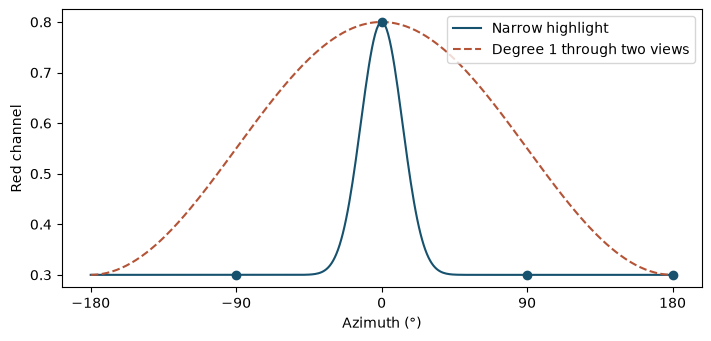

In [9]:
degrees = np.linspace(-180, 180, 361)
cosine = np.cos(np.deg2rad(degrees))
target = .30 + .50 * np.maximum(cosine, 0) ** 20
first_degree = .55 + .25 * cosine
fig, ax = plt.subplots(figsize=(7, 3.3), layout="constrained")
ax.plot(degrees, target, color="#16516e",
        label="Узкий блик" if ru else "Narrow highlight")
ax.plot(degrees, first_degree, "--", color="#b45336",
        label="Степень 1 по двум видам" if ru else "Degree 1 through two views")
ax.scatter([-90, 0, 90, 180], [.30, .80, .30, .30], color="#16516e", zorder=3)
ax.set(xlabel="Азимут (°)" if ru else "Azimuth (°)",
       ylabel="Красный канал" if ru else "Red channel", xticks=[-180,-90,0,90,180])
ax.legend()
display(fig)
plt.close(fig)

## Experiments and worked answers

What does the opposite side of the sphere look like? How could the model switch to a splat-to-camera arrow while preserving its appearance?

<details><summary>Worked answer</summary>

At the opposite direction all three linear maps reverse sign. Red becomes $0.5-0.156353+0.175897=0.519544$. Degree zero is identical on both sides. To translate the model between opposite conventions, we also reverse the signs of its three degree-one coefficients. The two minus signs in each product cancel.

</details>

**A different constant color.** A splat should have RGB $(0.2,0.5,0.8)$ from every direction. Which three numbers would stay in a degree-zero file?

<details><summary>Worked answer</summary>

For each channel the constant map gives $0.5+C_0a_0$. Subtracting $0.5$ from the desired RGB leaves $(-0.3,0,+0.3)$. Dividing each component by $0.282095$ gives approximately $(-1.0635,0,+1.0635)$. The negative red coefficient is perfectly usable. Multiplying it by the map just subtracts $0.3$ from gray. Moving the camera around the splat keeps that operation unchanged.

</details>

**A ray just off the horizontal plane.** Every parameter is known except $g_y$. After subtracting the known baseline and the $x$ and $z$ contributions, a camera with $d_y=0.02$ has a red remainder of $0.004$. How reliable is this measurement if the pixel itself could be off by $0.01$?

<details><summary>Worked answer</summary>

The remainder is the term $g_y d_y$. Division gives $g_y=0.004/0.02=0.20$. The same operation divides the possible error by $0.02$, putting the coefficient error as high as $0.01/0.02=0.50$, larger than the estimate itself. At $d_y=1$, with the same pixel precision and the other terms still known, the coefficient error would be only $0.01$. Both rays had a nonzero vertical component, but the almost horizontal one carried very little information about it.

</details>

**The rim of the cup gets lighter.** Two views of the rim have red $0.76$ and $0.88$ over white. Their known local opacities are $0.8$ and $0.4$. What is the splat's own red in each case? Does this pair require a directional coefficient?

<details><summary>Worked answer</summary>

In the first pixel the background supplies $1-0.8=0.2$. The splat color is $(0.76-0.2)/0.8=0.70$. In the second the background contributes $0.6$, giving $(0.88-0.6)/0.4=0.70$. A single color explains both observations. Fitting harmonics directly to $0.76$ and $0.88$ would store a spurious dependence on viewing angle. This ties the color model back to the previous lesson and gives us a reason to look at images from multiple cameras in the next block.

</details>